from SSVEPAnalysisToolbox.datasets import BenchmarkDataset
dataset = BenchmarkDataset(path = '2016_Tsinghua_SSVEP_database')

In [45]:
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from scipy import signal
from scipy.signal import butter, sosfilt, sosfreqz
from scipy.linalg import eigh

In [46]:
mat = scipy.io.loadmat('./sample_data/SSVEP_Data/S2.mat')
tr_cnt = np.array(mat.get('data'))

tr_Label = np.array(range(40))
tr_Label = np.tile(tr_Label, reps=6)

In [47]:
print(tr_cnt.shape)
print(tr_Label.shape)

(64, 1500, 40, 6)
(240,)


In [48]:
Channels = [
        'FP1', 'FPZ', 'FP2', 'AF3', 'AF4', 'F7', 'F5', 'F3', 'F1', 'FZ', 'F2', 'F4', 'F6', 'F8',
        'FT7', 'FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'FT8',
        'T7', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'T8',
        'M1', 'TP7', 'CP5', 'CP3', 'CP1', 'CPZ', 'CP2', 'CP4', 'CP6', 'TP8', 'M2',
        'P7', 'P5', 'P3', 'P1', 'P2', 'P4', 'P6', 'P8',
        'PO7', 'PO5', 'PO3', 'POz', 'PO4', 'PO6', 'PO8',
        'CB1', 'O1', 'Oz', 'O2', 'CB2'
]

ch_oz = 61
ch_o = [60, 61, 62]
ch_idx = [52, 53, 54, 55, 56, 57, 58, 60, 61, 62]

In [49]:
def fft(dat, fs = 250):
    # Compute the FFT
    fft_signal = np.fft.fft(dat)
    frequencies = np.fft.fftfreq(len(fft_signal), 1/fs)

    # Calculate the amplitude spectrum
    amplitude_spectrum = 2 * np.abs(fft_signal) / len(fft_signal)

    # Plot the amplitude spectrum
    #plt.subplot(4, 1, 1)
    plt.plot(frequencies[:len(frequencies)//2], amplitude_spectrum[:len(amplitude_spectrum)//2])
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.title("Frequency Domain (FFT) of EEG Signal")
    plt.tight_layout()
    plt.show()

In [50]:
def Bandpass(dat, freq = [5, 45], fs = 250):
    sos = butter(5, freq, 'band', fs=250, output='sos')
    fdat = list()
    for i in range(np.size(dat, 1)):
        tm = signal.sosfilt(sos, dat[:,i])
        fdat.append(tm)
    return np.array(fdat).transpose()

In [51]:
# (64, 1500, 40, 6)
def seg(dat, ival = [125,1375]): # 0.5-5.5s
    sdat = list()
    for i in range(np.size(dat, 3)):
        for j in range(np.size(dat, 2)):
            lag = range(ival[0], ival[1])
            sdat.append(dat[:, lag, j, i] )
    return np.array(sdat)

In [52]:
def generate_reference_signals(fs, num_samples, frequencies, num_harmonics=3):
    t = np.arange(num_samples) / fs
    reference_signals = []

    for freq in frequencies:
        signals = []
        for h in range(1, num_harmonics + 1):
            signals.append(np.sin(2 * np.pi * freq * h * t))
            signals.append(np.cos(2 * np.pi * freq * h * t))
        reference_signals.append(np.vstack(signals).T)

    return reference_signals

In [53]:
print(tr_cnt.shape)
print(tr_Label.shape)

(64, 1500, 40, 6)
(240,)


In [54]:
# Define parameters
fs = 250  # Sampling frequency (Hz)
duration = 5  # Duration of the signal (seconds)

seg_orgin = seg(tr_cnt)
seg_orgin = np.transpose(seg_orgin, (0, 2, 1))

In [55]:
seg_bandpass = list()
for i in range(np.size(seg_orgin, 0)):
    seg_bandpass.append(Bandpass(seg_orgin[i, :, :]) )

In [56]:
seg_orgin = np.transpose(seg_orgin, (1, 0, 2))
seg_bandpass = np.transpose(seg_bandpass, (1, 0, 2))


In [57]:

print(seg_orgin.shape)
print(seg_bandpass.shape)


(1250, 240, 64)
(1250, 240, 64)


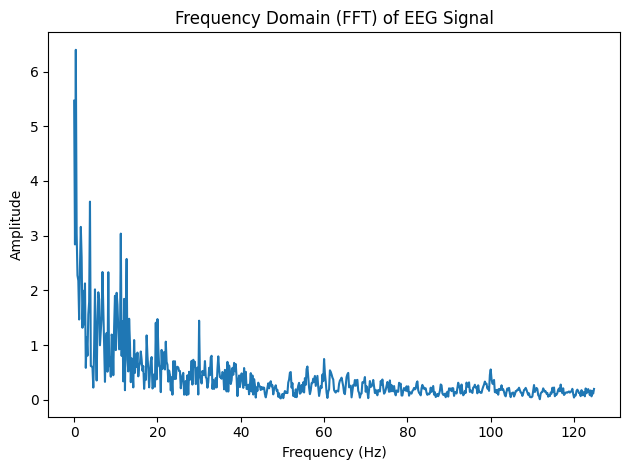

In [58]:
ff = seg_orgin[:,2,ch_oz]
ff = ff.reshape(1250, order = "F")
fft(ff)

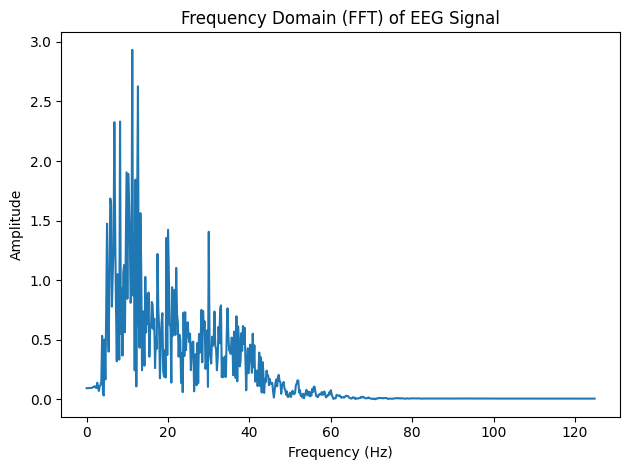

In [37]:
ff = seg_bandpass[:,2,ch_oz]
ff = ff.reshape(1250, order = "F")
fft(ff)

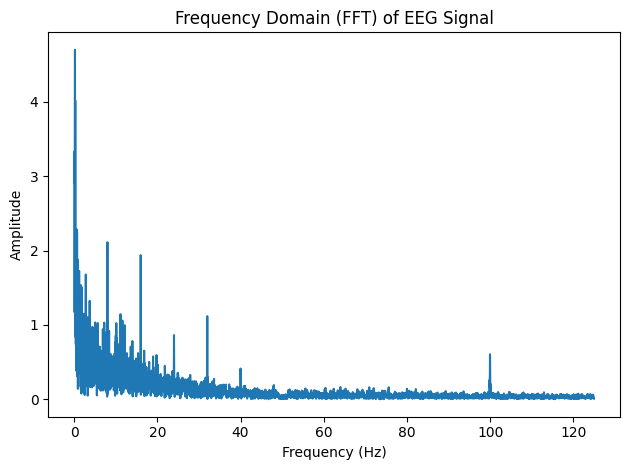

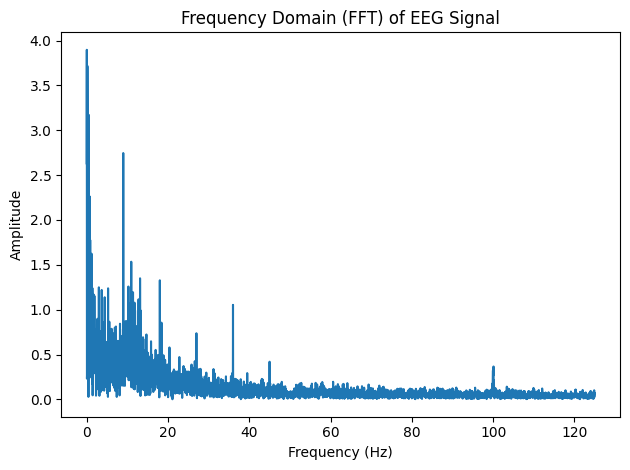

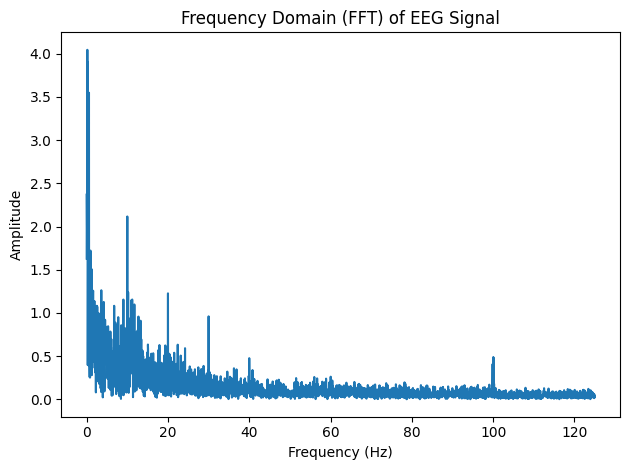

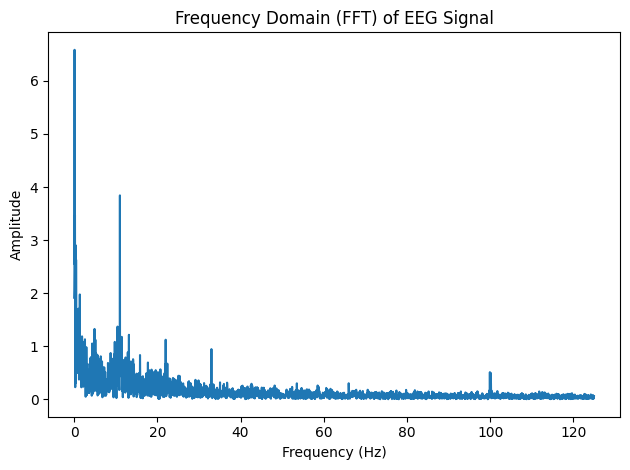

In [38]:
# frequencies = [12, 8.57, 6.67, 5.45]  # Stimulation frequencies (Hz)
for i in range(4):
    f = seg_orgin[:,tr_Label[:]==i, ch_oz]
    f = f.reshape(7500, order = 'F')
    fft(f)

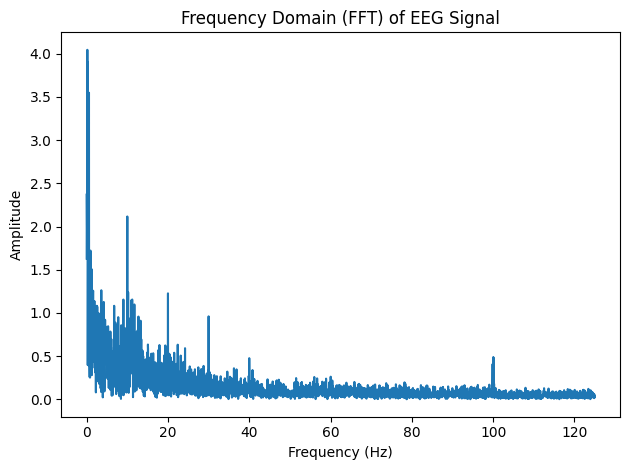

In [39]:
f = seg_orgin[:,tr_Label[:]==2, ch_oz]
f = f.reshape(7500, order = 'F')
fft(f)

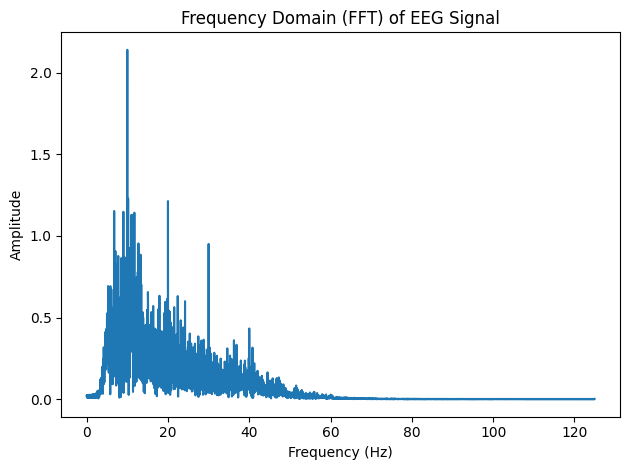

In [40]:
f = seg_bandpass[:,tr_Label[:]==2, ch_oz]
f = f.reshape(7500, order = 'F')
fft(f)

In [59]:
frequencies = [  8,   9,   10,   11,   12,   13,   14,   15,
               8.2, 9.2, 10.2, 11.2, 12.2, 13.2, 14.2, 15.2,
               8.4, 9.4, 10.4, 11.4, 12.4, 13.4, 14.4, 15.4,
               8.6, 9.6, 10.6, 11.6, 12.6, 13.6, 14.6, 15.6,
               8.8, 9.8, 10.8, 11.8, 12.8, 13.8, 14.8, 15.8]  # Stimulation frequencies (Hz)
# Generate reference signals
reference_signals = generate_reference_signals(fs, 1250, frequencies)

In [60]:
def myCCA(dat, ref):
    # dat = (t, dim), (1250, 62)
    # ref = (t, dim), (1250, 6)
    L = np.size(ref, 0)

    R_xx = np.cov(dat.T)  # (62, 62)
    R_yy = np.cov(ref.T)  # (6, 6)

    R_xy = np.matmul(dat.T,ref)/L # (62, 6) np.cov(eeg_data.T, ref.T)
    R_yx = np.matmul(ref.T,eeg_data)/L # (6, 62) np.cov(ref.T, eeg_data.T)

    mul = np.matmul
    inv = np.linalg.inv

    R_x = mul(mul(mul(inv(R_xx), R_xy),inv(R_yy)), R_yx)
    # (62, 62)x(62, 6)x(6, 6)x(6, 62) = (62, 62)
    R_y = mul(mul(mul(inv(R_yy), R_yx),inv(R_xx)), R_xy)
    # (6, 6)x(6, 62)x(62, 62)x(62, 6) = (6, 6)
    L, C = eigh(R_x)
    idx = np.argsort(L)[::-1]
    L = L[idx]
    C = C[:,idx]
    a = C[:,0]

    L, C = eigh(R_y)
    idx = np.argsort(L)[::-1]
    L = L[idx]
    C = C[:,idx]
    b = C[:,0]

    cca_eeg = mul(a, dat.T)
    cca_ref = mul(b, ref.T)
    r = mul(cca_eeg, cca_ref.T)/np.sqrt(mul(cca_eeg, cca_eeg)*mul(cca_ref, cca_ref))

    return a, b, r

In [61]:
reference_signals[0].shape

(1250, 6)

In [62]:
ch_idx = list(range(64))
ch_idx.remove(1) # FPZ
ch_idx.remove(9) # FZ

out2 = []
for i in range(240):
    eeg_data = seg_orgin[:,i,ch_idx]
    correlations = []
    for ref in reference_signals:
        [a, b, r] = myCCA(eeg_data, ref)
        correlations.append(np.abs(r))
        print(r)

    # Find the frequency with the highest correlation
    max_corr_freq = frequencies[np.argmax(correlations)]
    out2.append(np.argmax(correlations))

# Y = np.argmax(tr_Label, axis = 0)
Y = tr_Label
np.sum(Y==out2) / len(out2)

스트리밍 출력 내용이 길어서 마지막 5000줄이 삭제되었습니다.
0.046286337980853666
0.11315257005665315
0.10214015727338085
0.2079150478474444
0.12809429000503297
0.00990588279451885
0.012654896382784398
-0.06066827715439303
0.06828435324920007
-0.15740526684757158
-0.09238837276398655
-0.18395261144794933
-0.0638591870707153
-0.01800534437872241
0.0729767476868761
-0.07387079417285507
0.09751297065025238
-0.05896561824426239
0.13407671187856807
0.22601429479909824
-0.003603565063403682
0.018660513790588504
0.04474196044735704
0.007173877351053201
0.08326793209485352
0.02396365756718473
0.16792135895168875
-0.28827148633405775
0.01939573503917061
-0.032326038739973445
-0.08626803921779704
0.020942904358801452
0.10048312315602813
0.14961685886223114
-0.15977094221779634
0.21637632238982676
-0.1437757460292624
-0.04670945997994673
0.07763553105991144
-0.05704876075631499
-0.04188636861199103
0.07614337060528378
-0.19515526082345142
-0.12427086598553772
0.11915109102985781
-0.06643678268152199
0.06931416077790205
-

np.float64(0.06666666666666667)

In [63]:
ch_idx = [ch_oz-1, ch_oz, ch_oz+1]

out2 = []

for i in range(240):
    eeg_data = seg_bandpass[:,i,ch_idx]
    correlations = []
    for ref in reference_signals:
        [a, b, r] = myCCA(eeg_data, ref)
        correlations.append(np.abs(r))

    # Find the frequency with the highest correlation
    max_corr_freq = frequencies[np.argmax(correlations)]
    out2.append(np.argmax(correlations))

# Y = np.argmax(tr_Label, axis = 0)
Y = tr_Label
np.sum(Y==out2) / len(out2)

np.float64(0.6916666666666667)